# Desafio: Regressão Aplicada à Engenharia de Materiais

### ETAPA 01 - IMPORTAÇÃO DE BIBLIOTECAS E LEITURA DO ARQUIVO

In [4]:
# Importando bibliotecas necessárias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Carregar o dataset
df = pd.read_csv("/921fdc75-83ac-43de-b0c7-980943fe9994.csv")

# Visualizar as primeiras linhas
df.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength,Strength Category
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28.0,79.99,Alto
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28.0,61.89,Alto
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270.0,40.27,Baixa
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365.0,41.05,Baixa
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360.0,44.30,Baixa


In [5]:
# Analisando as informações gerais dos dados do dataset
print("\nInformações do dataset:")
df.info()


Informações do dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2029 entries, 0 to 2028
Data columns (total 10 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Cement                         2029 non-null   float64
 1   Blast Furnace Slag             2029 non-null   float64
 2   Fly Ash                        2029 non-null   float64
 3   Water                          2029 non-null   float64
 4   Superplasticizer               2029 non-null   float64
 5   Coarse Aggregate               2029 non-null   float64
 6   Fine Aggregate                 2029 non-null   float64
 7   Age                            2029 non-null   float64
 8   Concrete compressive strength  2020 non-null   float64
 9   Strength Category              2029 non-null   object 
dtypes: float64(9), object(1)
memory usage: 158.6+ KB


### ETAPA 02 - ANÁLISE EXPLORATÓRIA DE DADOS (EDA)

In [6]:
# Estatísticas descritivas
print("\nEstatísticas descritivas:")
df.describe()


Estatísticas descritivas:


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
count,2029.000000,2029.000000,2029.000000,2029.000000,2029.000000,2029.000000,2029.000000,2029.000000,2020.000000
mean,415.147610,107.776688,78.604091,264.240315,9.045293,1444.538492,1139.313258,67.255643,35.886683
std,237.133806,145.230234,106.149019,111.056771,10.239884,604.194394,481.913282,103.260526,16.860121
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.100000
25%,250.000000,0.000000,0.000000,182.000000,0.000000,967.100000,776.400000,14.000000,23.500000
50%,350.400000,26.000000,0.000000,206.000000,7.800000,1104.000000,889.000000,28.000000,34.675000
75%,512.400000,187.000000,136.200000,345.800000,13.600000,1911.800000,1502.800000,75.600000,46.230000
max,1487.600000,923.700000,500.900000,639.900000,83.700000,3150.000000,2779.300000,1022.000000,87.200000


In [7]:
# Verificar valores ausentes
print("\nValores ausentes por coluna:")
df.isnull().sum()


Valores ausentes por coluna:


,0
Cement,0
Blast Furnace Slag,0
Fly Ash,0
Water,0
Superplasticizer,0
Coarse Aggregate,0
Fine Aggregate,0
Age,0
Concrete compressive strength,9
Strength Category,0


In [8]:
# Eliminando os dados ausentes
df_clean = df.dropna()
df_clean.isnull().sum()

,0
Cement,0
Blast Furnace Slag,0
Fly Ash,0
Water,0
Superplasticizer,0
Coarse Aggregate,0
Fine Aggregate,0
Age,0
Concrete compressive strength,0
Strength Category,0


In [9]:
#One-Hot Encoding para a coluna Strength Category (object)
df_clean_encoded = pd.get_dummies(df, drop_first=True)
df_clean_encoded.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength,Strength Category_Baixa
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28.0,79.99,False
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28.0,61.89,False
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270.0,40.27,True
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365.0,41.05,True
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360.0,44.30,True


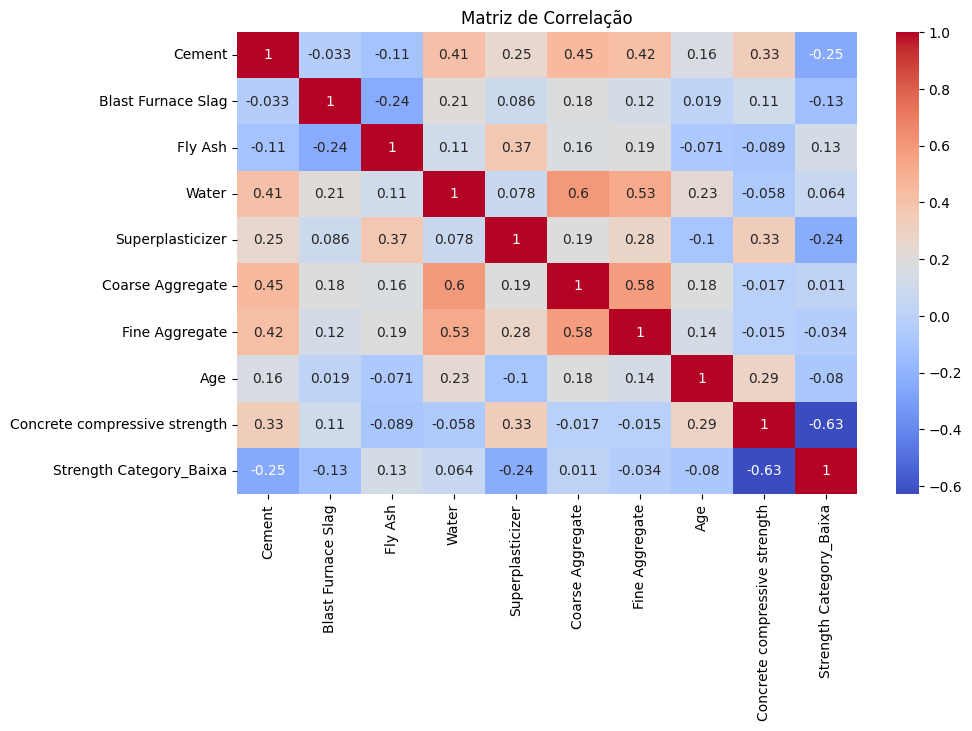

In [10]:
# Correlação entre as variáveis
plt.figure(figsize=(10,6))
sns.heatmap(df_clean_encoded.corr(), annot=True, cmap="coolwarm")
plt.title("Matriz de Correlação")
plt.show()

In [11]:
# Correlação de cada variável com a resistência do concreto
print("\nCorrelação de cada variável com a resistência do concreto (Concrete compressive strength):\n")
corr_strength = df_clean_encoded.corr()['Concrete compressive strength'].sort_values(ascending=False)
corr_strength


Correlação de cada variável com a resistência do concreto (Concrete compressive strength):



,Concrete compressive strength
Concrete compressive strength,1.000000
Superplasticizer,0.329791
Cement,0.327826
Age,0.290215
Blast Furnace Slag,0.106848
Fine Aggregate,-0.015073
Coarse Aggregate,-0.017209
Water,-0.057646
Fly Ash,-0.089434
Strength Category_Baixa,-0.627539


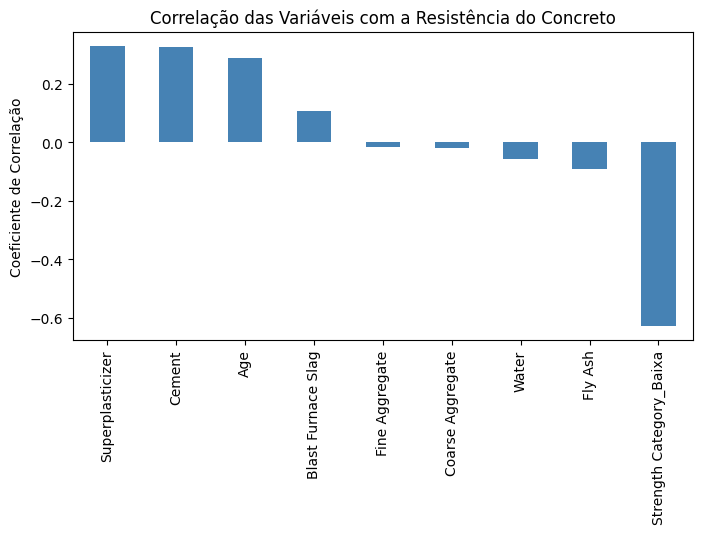

In [12]:
# Visualizar graficamente a correlação com Concrete compressive strength
plt.figure(figsize=(8,4))
corr_strength.drop('Concrete compressive strength').plot(kind='bar', color='steelblue')
plt.title("Correlação das Variáveis com a Resistência do Concreto")
plt.ylabel("Coeficiente de Correlação")
plt.show()

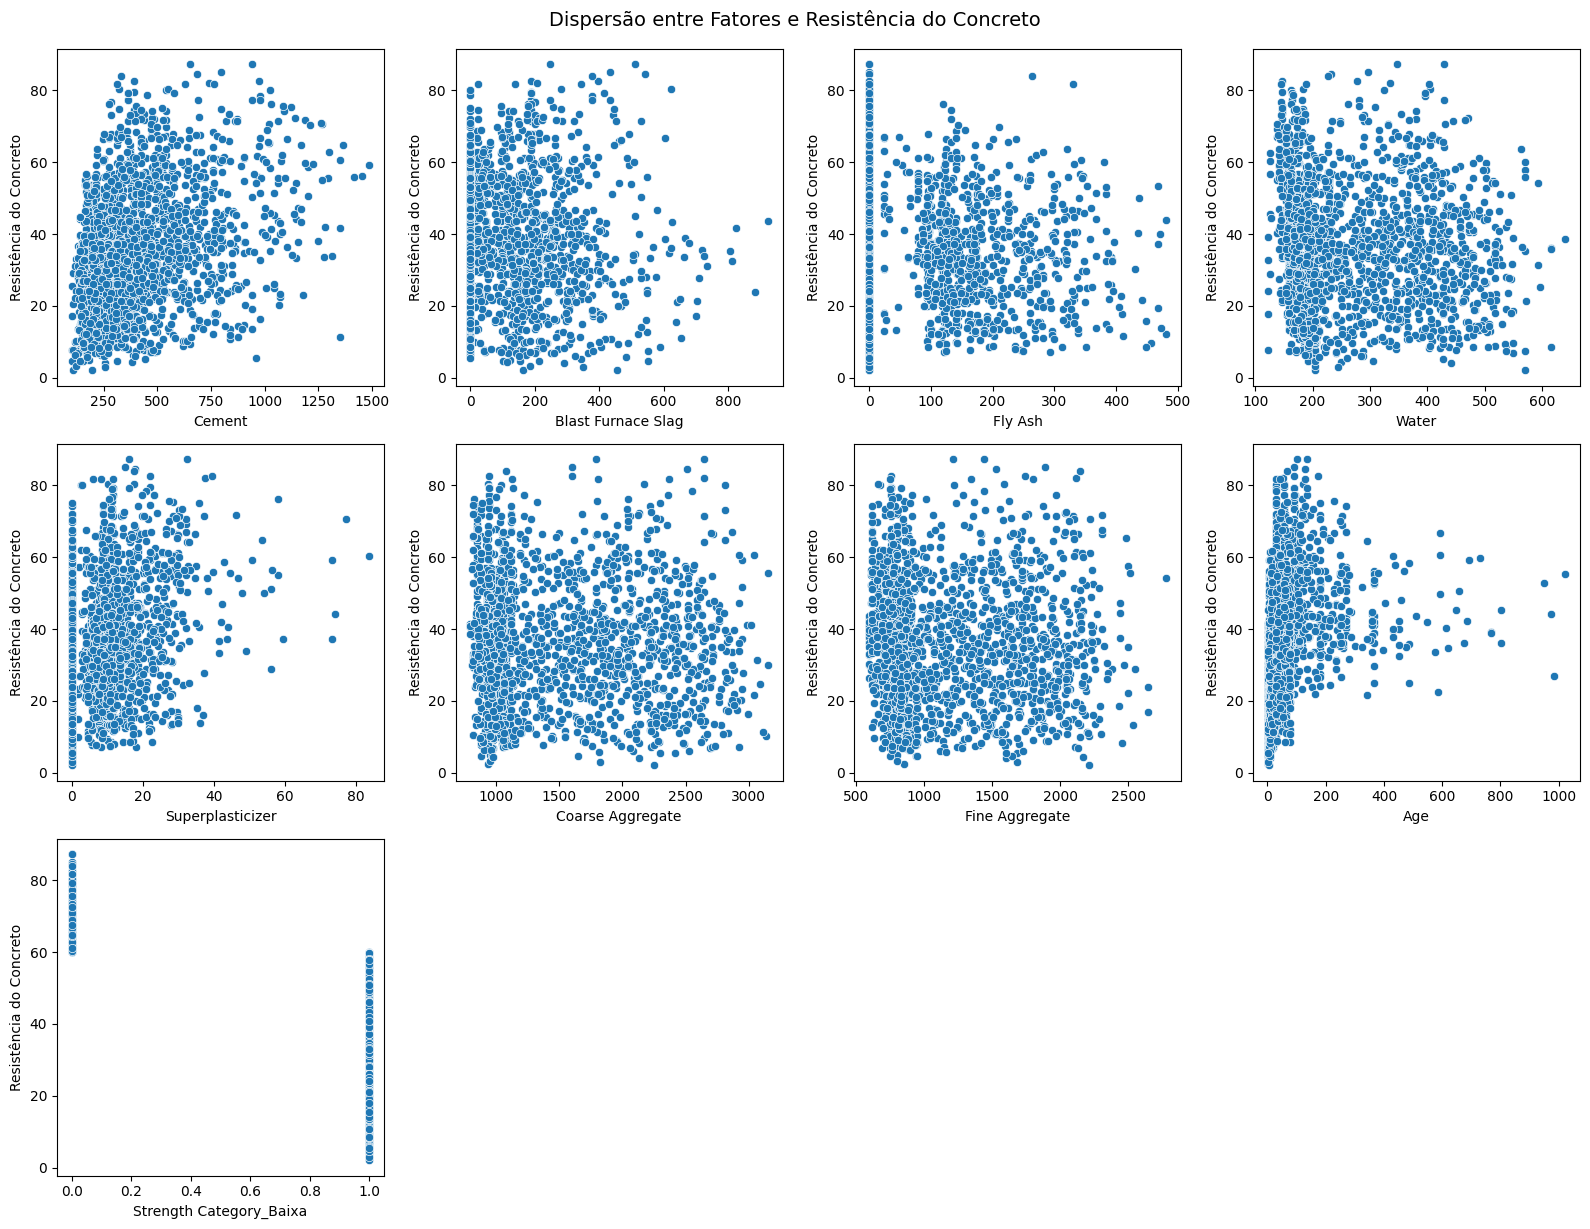

In [13]:
# Gráficos de dispersão (Scatter plots)
cols_to_plot = df_clean_encoded.columns.drop('Concrete compressive strength')

# Gera automaticamente o número de linhas e colunas conforme o total de variáveis
cols = 4
rows = int(len(cols_to_plot) / cols) + 1

plt.figure(figsize=(16, 4 * rows))
for i, col in enumerate(cols_to_plot, 1):
    plt.subplot(rows, cols, i)
    sns.scatterplot(x=df_clean_encoded[col], y=df_clean_encoded['Concrete compressive strength'])
    plt.xlabel(col)
    plt.ylabel('Resistência do Concreto')
    plt.tight_layout()

plt.suptitle("Dispersão entre Fatores e Resistência do Concreto", y=1.02, fontsize=14)
plt.show()

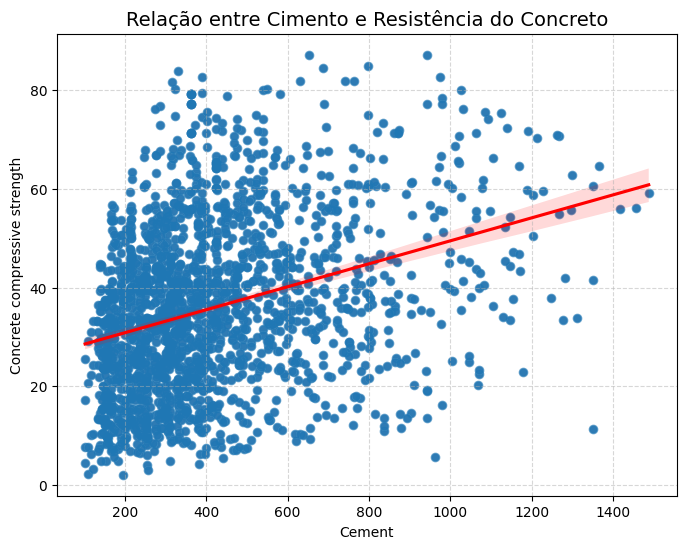

In [14]:
# Relação entre Cimento e Resistência do Concreto
plt.figure(figsize=(8,6))
sns.scatterplot(
    x=df_clean_encoded['Cement'],
    y=df_clean_encoded['Concrete compressive strength'],
    color='steelblue'
)
plt.title("Relação entre Cimento e Resistência do Concreto", fontsize=14)
plt.xlabel("Quantidade de Cimento")
plt.ylabel("Resistência do Concreto")
plt.grid(True, linestyle='--', alpha=0.5)

sns.regplot(
    x=df_clean_encoded['Cement'],
    y=df_clean_encoded['Concrete compressive strength'],
    scatter_kws={'alpha':0.6},
    line_kws={'color':'red'}
)
plt.show()

### Há uma tendência positiva, ou seja, conforme a quantidade de cimento aumenta, a resistência do concreto tende a aumentar também.

In [15]:
df

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength,Strength Category
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28.0,79.99,Alto
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28.0,61.89,Alto
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270.0,40.27,Baixa
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365.0,41.05,Baixa
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360.0,44.30,Baixa
...,...,...,...,...,...,...,...,...,...,...
2024,449.2,0.0,0.0,323.3,17.4,2229.0,1314.7,30.8,39.10,Baixa
2025,428.2,387.1,301.6,402.7,27.0,1525.3,1439.4,47.6,NaN,Baixa
2026,183.1,310.3,0.0,380.0,17.0,2604.7,1299.4,30.8,24.20,Baixa
2027,651.0,399.8,0.0,386.2,19.0,2102.9,1125.6,72.8,40.80,Baixa


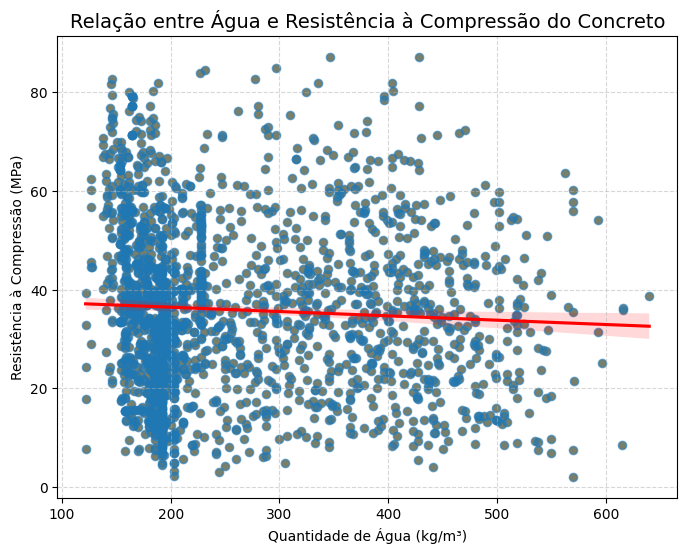

In [16]:
# Relação entre quantidade de Água e a Resistência do Concreto
plt.figure(figsize=(8,6))
sns.scatterplot(
    x=df_clean_encoded['Water'],
    y=df_clean_encoded['Concrete compressive strength'],
    color='darkorange'
)
sns.regplot(
    x=df_clean_encoded['Water'],
    y=df_clean_encoded['Concrete compressive strength'],
    scatter_kws={'alpha':0.6},
    line_kws={'color':'red'}
)
plt.title("Relação entre Água e Resistência à Compressão do Concreto", fontsize=14)
plt.xlabel("Quantidade de Água (kg/m³)")
plt.ylabel("Resistência à Compressão (MPa)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Há uma leve tendência de quanto mais água, menor a resistência do concreto, conforme linha vermelha do gráfico que representa uma linha de regressão.


In [17]:
# Aqui, vou utilizar o dataset original com a coluna 'Strength Category' sem o One-Hot Encoding

# Eliminando os dados ausentes do dataset original df
df_clean = df.dropna()
df_clean.isnull().sum()

,0
Cement,0
Blast Furnace Slag,0
Fly Ash,0
Water,0
Superplasticizer,0
Coarse Aggregate,0
Fine Aggregate,0
Age,0
Concrete compressive strength,0
Strength Category,0


Resistência média por categoria de força:
Strength Category
Baixa    32.488236
Alto     68.810265
Name: Concrete compressive strength, dtype: float64


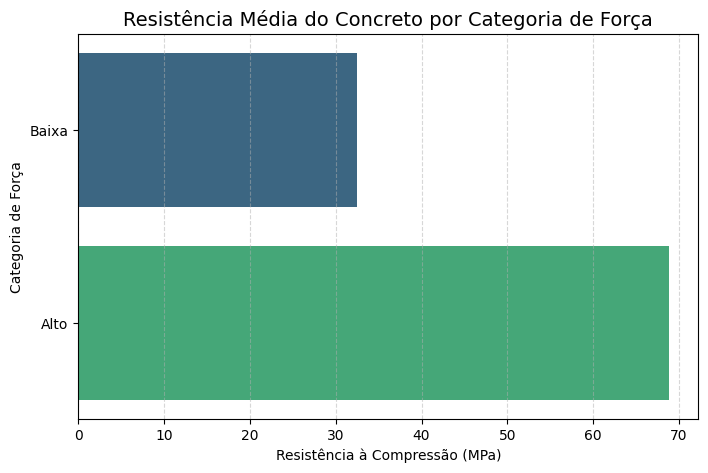

In [18]:
# Cálculo da resistência média por categoria
mean_strength = df_clean.groupby('Strength Category')['Concrete compressive strength'].mean().sort_values()

print("Resistência média por categoria de força:")
print(mean_strength)

# Gráfico de barras horizontais
plt.figure(figsize=(8,5))
sns.barplot(
    x=mean_strength.values,
    y=mean_strength.index,
    hue=mean_strength.index,
    dodge=False,
    legend=False,
    orient='h',
    palette='viridis'
)

plt.title("Resistência Média do Concreto por Categoria de Força", fontsize=14)
plt.xlabel("Resistência à Compressão (MPa)")
plt.ylabel("Categoria de Força")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.show()

## Categoria Baixa -> ~32 MPa -> Concretos mais fracos, provavelmente mais água ou menos cimento

## Categoria Alta -> ~69 MPa -> Concretos mais resistentes, geralmente com mais cimento ou melhor proporção água/cimento


### Etapa 03 - Construção e Avaliação de Modelos de Regressão

In [21]:
# Definindo temporariamente a variável alvo y a partir do DataFrame codificado para verificar valores nulos
y = df_clean_encoded['Concrete compressive strength']

# Verificando se há valores ausentes na variável alvo y
y.isna().sum()

np.int64(9)

In [22]:
# Remove linhas onde a variável alvo é nula
df_model = df_clean_encoded.dropna(subset=['Concrete compressive strength'])

In [23]:
# Definir variáveis independentes (X) e dependente (y)
X = df_model.drop('Concrete compressive strength', axis=1)
y = df_model['Concrete compressive strength']

# Dividir entre treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [24]:
# Random Forest Regressor
model_rf = RandomForestRegressor(n_estimators=200, random_state=42)
model_rf.fit(X_train, y_train)
y_pred_rf = model_rf.predict(X_test)

# Métricas de avaliação
r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

print("\n🔹 Random Forest Regressor:")
print(f"R²: {r2_rf:.4f}")
print(f"MAE: {mae_rf:.4f}")
print(f"RMSE: {rmse_rf:.4f}")


🔹 Random Forest Regressor:
R²: 0.8163
MAE: 5.0260
RMSE: 7.0849


In [25]:
# Regressão Linear
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model_lr = LinearRegression()
model_lr.fit(X_train_scaled, y_train)
y_pred_lr = model_lr.predict(X_test_scaled)

# Métricas de avaliação
r2_lr = r2_score(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

print("\n🔹 Regressão Linear:")
print(f"R²: {r2_lr:.4f}")
print(f"MAE: {mae_lr:.4f}")
print(f"RMSE: {rmse_lr:.4f}")


🔹 Regressão Linear:
R²: 0.5193
MAE: 9.3446
RMSE: 11.4597


## Interpretação
### Random Forest Regressor
Apresentou R² = 0.8163, ou seja, o modelo consegue explicar cerca de 81% da variação da resistência do concreto.
Tanto o MAE (erro médio) quanto o RMSE (erro médio mais sensível a erros grandes) foram bem menores, indicando previsões mais precisas e estáveis.

### Regressão Linear
Obteve R² = 0.5193, conseguindo explicar apenas 52% da variação da resistência.
Os erros (MAE e RMSE) foram quase o dobro dos obtidos com o Random Forest.
Isso indica que o comportamento da mistura de concreto não é linear, e por isso um modelo linear não consegue capturar suas relações de forma adequada.

### Conclusão: O modelo linear não representa bem os dados. O melhor modelo a se aplicar nesse caso é o Random Forest.

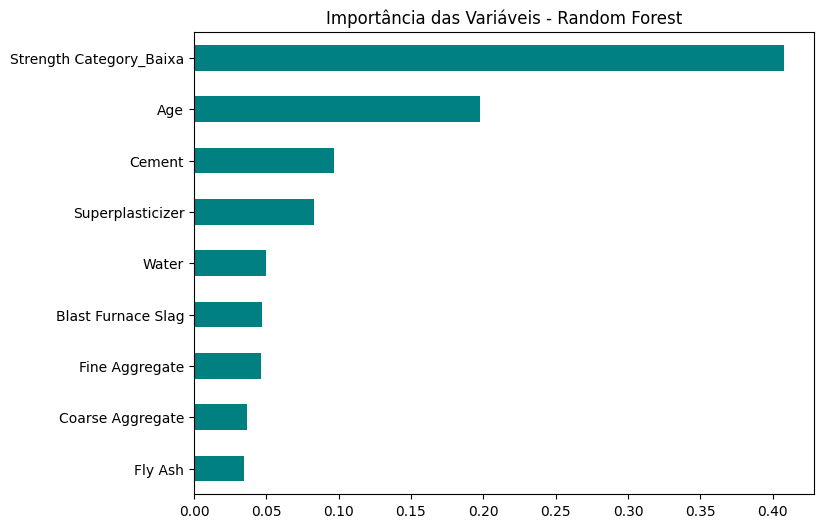

In [26]:
# IMPORTÂNCIA DAS VARIÁVEIS
importances = pd.Series(model_rf.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(8,6))
importances.plot(kind='barh', color='teal')
plt.title("Importância das Variáveis - Random Forest")
plt.show()

In [27]:
# Criar um dicionário com os valores informados
nova_amostra = {
    'Cement': 550,
    'Blast Furnace Slag': 150,
    'Fly Ash': 0,
    'Water': 180,
    'Superplasticizer': 2.5,
    'Coarse Aggregate': 1000,
    'Fine Aggregate': 700,
    'Age': 25,
}

# Converter para DataFrame
nova_amostra_df = pd.DataFrame([nova_amostra])

# Garantir que as colunas estão na mesma ordem do modelo
nova_amostra_df = nova_amostra_df.reindex(columns=X_train.columns, fill_value=0)

# Fazer a previsão
pred_nova_resistencia = model_rf.predict(nova_amostra_df)

print(f"\n Resistência prevista do concreto: {pred_nova_resistencia[0]:.2f} MPa")


 Resistência prevista do concreto: 71.60 MPa


A partir da composição fornecida, o modelo Random Forest previu uma resistência de 71.60 MPa.
Esse valor indica que a mistura projetada tende a apresentar uma classe de resistência elevada, o que pode ser adequado para estruturas que exigem maior desempenho mecânico, como pilares, vigas e elementos de fundação.
